In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re

In [ ]:
df=pd.read_csv("/content/Processed_Flipdata - Processed_Flipdata.csv")
df.head(12)

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
5,5,Infinix HOT 30i,Glacier Blue,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
6,6,Infinix HOT 30i,Mirror Black,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
7,7,Infinix HOT 30i,Diamond White,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"
8,8,Infinix HOT 30i,Diamond White,64,4,5000,50MP,5MP,1,16.76,G37,"7,999"
9,9,Infinix HOT 30i,Mirror Black,64,4,5000,50MP,5MP,1,16.76,G37,"7,999"


In [ ]:
df.tail()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
536,637,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50MP,12MP,0,15.49,Qualcomm Snapdragon 8 Gen 2,"79,999"
537,638,LAVA Z21,Cyan,32,2,3100,5MP,2MP,0,12.70,Octa Core,"5,998"
538,639,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,"9,990"
539,641,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50MP,32MP,0,16.26,"Exynos 1380, Octa Core","38,999"
540,642,OPPO A77,Sky Blue,128,4,5000,50MP,8MP,0,16.66,Mediatek Helio G35,"15,999"


In [ ]:
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='object')

In [ ]:
df.shape

(541, 12)

In [ ]:
df.iloc[145]

,145
Unnamed: 0,145
Model,REDMI Note 12 5G
Colour,Frosted Green
Memory,128
RAM,6
Battery_,5000
Rear Camera,48MP
Front Camera,13MP
AI Lens,0
Mobile Height,16.94


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    object 
dtypes: float64(1), int64(5), object(6)
memory usage: 50.8+ KB


In [ ]:
df[["Memory","RAM","Battery_","Mobile Height","Prize"]].describe()

,Memory,RAM,Battery_,Mobile Height
count,541.000000,541.000000,541.000000,541.000000
mean,110.550832,5.397412,4871.587800,16.431201
std,60.600694,1.984923,780.148862,2.523553
min,16.000000,2.000000,800.000000,4.500000
25%,64.000000,4.000000,5000.000000,16.510000
50%,128.000000,6.000000,5000.000000,16.710000
75%,128.000000,8.000000,5000.000000,16.940000
max,256.000000,8.000000,7000.000000,41.940000


In [ ]:
df.describe()

,Unnamed: 0,Memory,RAM,Battery_,AI Lens,Mobile Height
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,289.711645,110.550832,5.397412,4871.587800,0.062847,16.431201
std,182.359185,60.600694,1.984923,780.148862,0.242911,2.523553
min,0.000000,16.000000,2.000000,800.000000,0.000000,4.500000
25%,135.000000,64.000000,4.000000,5000.000000,0.000000,16.510000
50%,273.000000,128.000000,6.000000,5000.000000,0.000000,16.710000
75%,434.000000,128.000000,8.000000,5000.000000,0.000000,16.940000
max,642.000000,256.000000,8.000000,7000.000000,1.000000,41.940000


In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
Model,0
Colour,0
Memory,0
RAM,0
Battery_,0
Rear Camera,0
Front Camera,0
AI Lens,0
Mobile Height,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df=df.drop_duplicates()
print(df)

     Unnamed: 0                  Model          Colour  Memory  RAM  Battery_  \
0             0        Infinix SMART 7     Night Black      64    4      6000   
1             1        Infinix SMART 7      Azure Blue      64    4      6000   
2             2           MOTOROLA G32    Mineral Gray     128    8      5000   
3             3               POCO C50      Royal Blue      32    2      5000   
4             4        Infinix HOT 30i        Marigold     128    8      5000   
..          ...                    ...             ...     ...  ...       ...   
536         637  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537         638               LAVA Z21            Cyan      32    2      3100   
538         639         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539         641  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540         642               OPPO A77        Sky Blue     128    4      5000   

    Rear Camera Front Camer

In [ ]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()
print(df)

     Unnamed: 0                  Model          Colour  Memory  RAM  Battery_  \
0             0        Infinix SMART 7     Night Black      64    4      6000   
1             1        Infinix SMART 7      Azure Blue      64    4      6000   
2             2           MOTOROLA G32    Mineral Gray     128    8      5000   
3             3               POCO C50      Royal Blue      32    2      5000   
4             4        Infinix HOT 30i        Marigold     128    8      5000   
..          ...                    ...             ...     ...  ...       ...   
536         637  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537         638               LAVA Z21            Cyan      32    2      3100   
538         639         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539         641  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540         642               OPPO A77        Sky Blue     128    4      5000   

    Rear Camera Front Camer

In [ ]:
# Rename columns for consistency
df.rename(columns={
    "Prize": "Price",
    "prize": "Price",
    "Colour": "Color"
}, inplace=True)
print(df)

     Unnamed: 0                  Model           Color  Memory  RAM  Battery_  \
0             0        Infinix SMART 7     Night Black      64    4      6000   
1             1        Infinix SMART 7      Azure Blue      64    4      6000   
2             2           MOTOROLA G32    Mineral Gray     128    8      5000   
3             3               POCO C50      Royal Blue      32    2      5000   
4             4        Infinix HOT 30i        Marigold     128    8      5000   
..          ...                    ...             ...     ...  ...       ...   
536         637  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537         638               LAVA Z21            Cyan      32    2      3100   
538         639         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539         641  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540         642               OPPO A77        Sky Blue     128    4      5000   

    Rear Camera Front Camer

In [ ]:
# Replace empty strings and common missing-value labels
df.replace(
    r"^\s*(|NA|N/A|NaN|null|None)\s*$",
    np.nan,
    regex=True,
    inplace=True
)

In [ ]:
#Standardize text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [ ]:
# Standardize Color values
if "Color" in df.columns:
    df["Color"] = df["Color"].str.title()

In [ ]:
#Convert numeric columns

numeric_columns = [
    "Memory",
    "RAM",
    "Battery_",
    "Rear Camera",
    "Front Camera",
    "AI Lens",
    "Mobile Height",
    "Price"
]
# Extract numbers from values such as 13MP or 6000mAh
for col in numeric_columns:
    if col in df.columns:
        cleaned = df[col].astype("string").str.replace(
            ",", "", regex=False
        )

        cleaned = cleaned.str.extract(
            r"(-?\d+(?:\.\d+)?)", expand=False
        )

        df[col] = pd.to_numeric(cleaned, errors="coerce")
print(df[numeric_columns].head(10))

   Memory  RAM  Battery_  Rear Camera  Front Camera  AI Lens  Mobile Height  \
0      64    4      6000           13             5        1          16.76   
1      64    4      6000           13             5        1          16.76   
2     128    8      5000           50            16        0          16.64   
3      32    2      5000            8             5        0          16.56   
4     128    8      5000           50             5        1          16.76   
5     128    8      5000           50             5        1          16.76   
6     128    8      5000           50             5        1          16.76   
7     128    8      5000           50             5        1          16.76   
8      64    4      5000           50             5        1          16.76   
9      64    4      5000           50             5        1          16.76   

   Price  
0   7299  
1   7299  
2  11999  
3   5649  
4   8999  
5   8999  
6   8999  
7   8999  
8   7999  
9   7999  


In [ ]:
#Values that should not be negative
non_negative_columns = [
    "Memory",
    "RAM",
    "Battery_",
    "Rear Camera",
    "Front Cam",
    "Mobile Height",
    "Price"
]

for col in non_negative_columns:
    if col in df.columns:
        df.loc[df[col] < 0, col] = np.nan

# AI Lens should be binary: 0 or 1
if "AI Lens" in df.columns:
    df.loc[~df["AI Lens"].isin([0, 1]), "AI Lens"] = np.nan

# Check inconsistent or invalid values
print("\nMissing values after type conversion:")
print(df.isnull().sum())




Missing values after type conversion:
Unnamed: 0       0
Model            0
Color            0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Price            0
dtype: int64


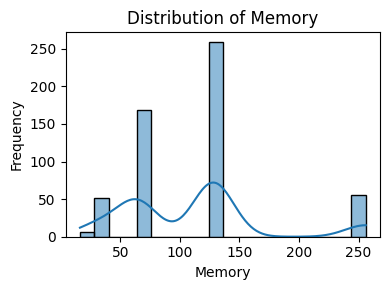

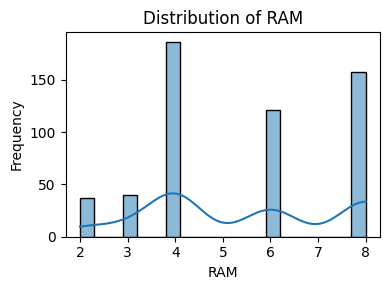

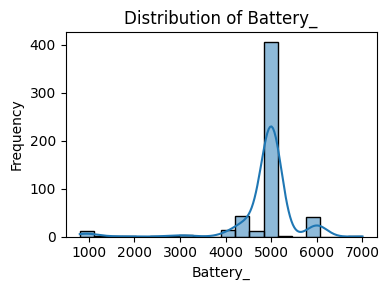

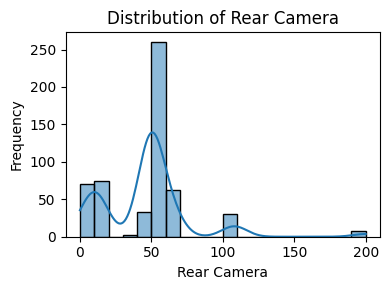

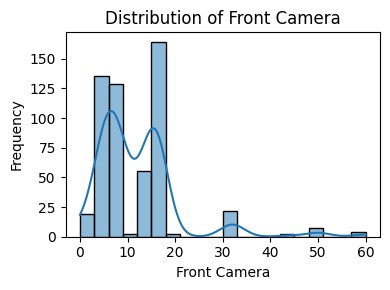

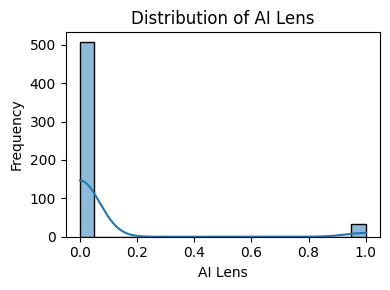

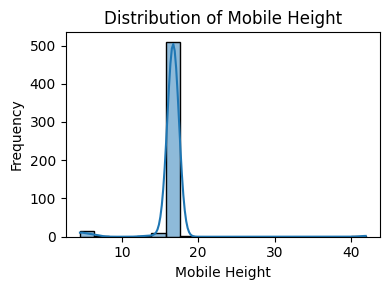

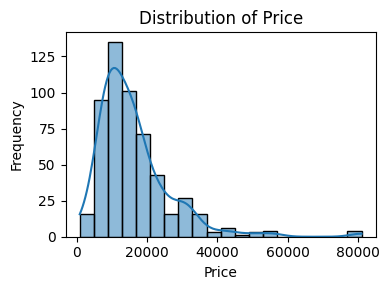

In [ ]:
#UNIVARIANT ANALYSIS:
for col in numeric_columns:
    plt.figure(figsize=(4,3))
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()


In [ ]:
print(f"\nStatistics for {col}:")
print("Mean:", df[col].mean())
print("Median:", df[col].median())
print("Standard deviation:", df[col].std())
print("Minimum:", df[col].min())
print("Maximum:", df[col].max())




Statistics for Price:
Mean: 16228.375231053604
Median: 13499.0
Standard deviation: 10793.588322328394
Minimum: 920
Maximum: 80999


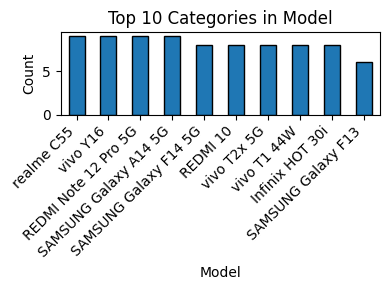

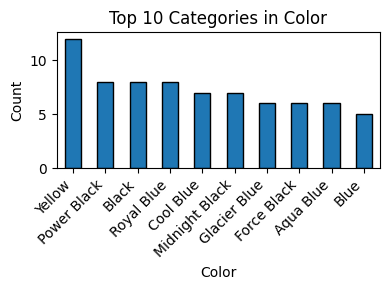

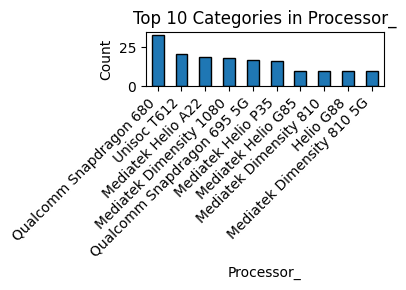

In [ ]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    plt.figure(figsize=(4,3))

    df[col].value_counts().head(10).plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title(f"Top 10 Categories in {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()
    plt.show()


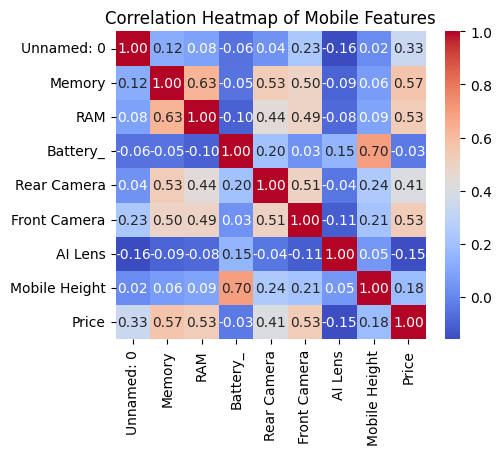

In [ ]:
#correaltion heatmap:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(5,4))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Heatmap of Mobile Features')
plt.show()

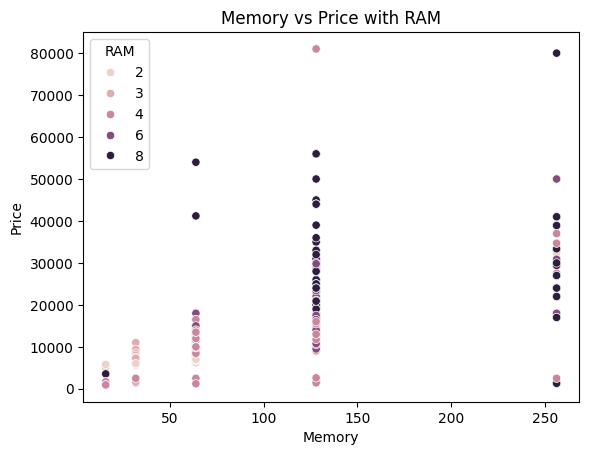

In [ ]:
#RAM, Memory and Price:
sns.scatterplot(
    data=df,
    x='Memory',
    y='Price',
    hue='RAM'
)
plt.title('Memory vs Price with RAM')
plt.show()


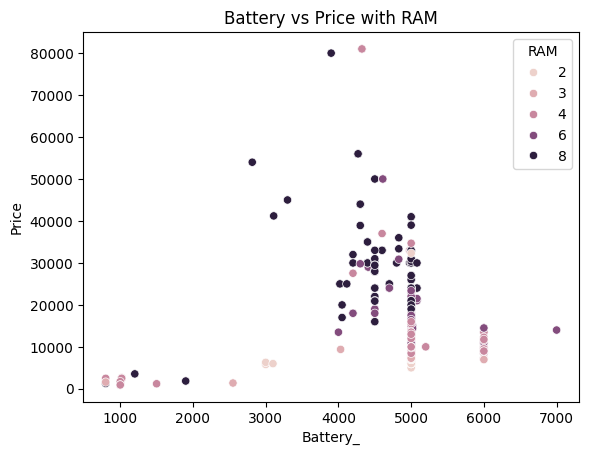

In [ ]:
#Battery, RAM and Price
sns.scatterplot(
    data=df,
    x='Battery_',
    y='Price',
    hue='RAM'
)
plt.title('Battery vs Price with RAM')
plt.show()


In [ ]:
df['RAM'] = pd.to_numeric(df['RAM'], errors='coerce')
df['Memory'] = pd.to_numeric(df['Memory'], errors='coerce')

df['Price'] = pd.to_numeric(
    df['Price'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

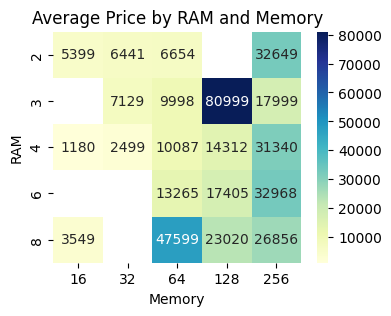

In [ ]:
#RAM and Memory vs Average Price
pivot_table = df.pivot_table(
    index='RAM',
    columns='Memory',
    values='Price',
    aggfunc='mean'
)
plt.figure(figsize=(4,3))
sns.heatmap(
    pivot_table,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)
plt.title('Average Price by RAM and Memory')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.metrics import r2_score, mean_absolute_error


In [ ]:
#Clean column names
df.columns = df.columns.str.strip()
print(df)


     Unnamed: 0                  Model           Color  Memory  RAM  Battery_  \
0             0        Infinix SMART 7     Night Black      64    4      6000   
1             1        Infinix SMART 7      Azure Blue      64    4      6000   
2             2           MOTOROLA G32    Mineral Gray     128    8      5000   
3             3               POCO C50      Royal Blue      32    2      5000   
4             4        Infinix HOT 30i        Marigold     128    8      5000   
..          ...                    ...             ...     ...  ...       ...   
536         637  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537         638               LAVA Z21            Cyan      32    2      3100   
538         639         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539         641  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540         642               OPPO A77        Sky Blue     128    4      5000   

     Rear Camera  Front Cam

In [ ]:
#Remove unnecessary index column, if present
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
print(df)

                     Model           Color  Memory  RAM  Battery_  \
0          Infinix SMART 7     Night Black      64    4      6000   
1          Infinix SMART 7      Azure Blue      64    4      6000   
2             MOTOROLA G32    Mineral Gray     128    8      5000   
3                 POCO C50      Royal Blue      32    2      5000   
4          Infinix HOT 30i        Marigold     128    8      5000   
..                     ...             ...     ...  ...       ...   
536  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537               LAVA Z21            Cyan      32    2      3100   
538         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540               OPPO A77        Sky Blue     128    4      5000   

     Rear Camera  Front Camera  AI Lens  Mobile Height  \
0             13             5        1          16.76   
1             13             5        1          16.76 

In [ ]:
 #Clean target variable
df['Price'] = pd.to_numeric(
    df['Price'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

df = df.dropna(subset=['Price']).copy()
print(df)


                     Model           Color  Memory  RAM  Battery_  \
0          Infinix SMART 7     Night Black      64    4      6000   
1          Infinix SMART 7      Azure Blue      64    4      6000   
2             MOTOROLA G32    Mineral Gray     128    8      5000   
3                 POCO C50      Royal Blue      32    2      5000   
4          Infinix HOT 30i        Marigold     128    8      5000   
..                     ...             ...     ...  ...       ...   
536  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537               LAVA Z21            Cyan      32    2      3100   
538         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540               OPPO A77        Sky Blue     128    4      5000   

     Rear Camera  Front Camera  AI Lens  Mobile Height  \
0             13             5        1          16.76   
1             13             5        1          16.76 

In [ ]:
#Create new useful features
# Total megapixels of rear and front cameras
df['Total_Camera_MP'] = (
    df['Rear Camera'].fillna(0) +
    df['Front Camera'].fillna(0)
)
print(df)

                     Model           Color  Memory  RAM  Battery_  \
0          Infinix SMART 7     Night Black      64    4      6000   
1          Infinix SMART 7      Azure Blue      64    4      6000   
2             MOTOROLA G32    Mineral Gray     128    8      5000   
3                 POCO C50      Royal Blue      32    2      5000   
4          Infinix HOT 30i        Marigold     128    8      5000   
..                     ...             ...     ...  ...       ...   
536  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537               LAVA Z21            Cyan      32    2      3100   
538         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540               OPPO A77        Sky Blue     128    4      5000   

     Rear Camera  Front Camera  AI Lens  Mobile Height  \
0             13             5        1          16.76   
1             13             5        1          16.76 

In [ ]:
#Storage-to-RAM ratio
df['Storage_RAM_Ratio'] = (
    df['Memory'] /
    df['RAM'].replace(0, np.nan)
)
print(df)

                     Model           Color  Memory  RAM  Battery_  \
0          Infinix SMART 7     Night Black      64    4      6000   
1          Infinix SMART 7      Azure Blue      64    4      6000   
2             MOTOROLA G32    Mineral Gray     128    8      5000   
3                 POCO C50      Royal Blue      32    2      5000   
4          Infinix HOT 30i        Marigold     128    8      5000   
..                     ...             ...     ...  ...       ...   
536  SAMSUNG Galaxy S23 5G           Cream     256    8      3900   
537               LAVA Z21            Cyan      32    2      3100   
538         Tecno Spark 8T  Turquoise Cyan      64    4      5000   
539  SAMSUNG Galaxy A54 5G    Awesome Lime     128    8      5000   
540               OPPO A77        Sky Blue     128    4      5000   

     Rear Camera  Front Camera  AI Lens  Mobile Height  \
0             13             5        1          16.76   
1             13             5        1          16.76 

In [ ]:
#Battery capacity per GB of RAM
df['Battery_RAM_Ratio'] = (
    df['Battery_'] /
    df['RAM'].replace(0, np.nan)
)

print("New extracted features:")
print(df[
    ['Total_Camera_MP', 'Storage_RAM_Ratio',
     'Battery_RAM_Ratio']
])
df.head()

New extracted features:
     Total_Camera_MP  Storage_RAM_Ratio  Battery_RAM_Ratio
0                 18               16.0             1500.0
1                 18               16.0             1500.0
2                 66               16.0              625.0
3                 13               16.0             2500.0
4                 55               16.0              625.0
..               ...                ...                ...
536               62               32.0              487.5
537                7               16.0             1550.0
538               58               16.0             1250.0
539               82               16.0              625.0
540               58               32.0             1250.0

[541 rows x 3 columns]


,Model,Color,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Price,Total_Camera_MP,Storage_RAM_Ratio,Battery_RAM_Ratio
0,Infinix SMART 7,Night Black,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299,18,16.0,1500.0
1,Infinix SMART 7,Azure Blue,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299,18,16.0,1500.0
2,MOTOROLA G32,Mineral Gray,128,8,5000,50,16,0,16.64,Qualcomm Snapdragon 680,11999,66,16.0,625.0
3,POCO C50,Royal Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,5649,13,16.0,2500.0
4,Infinix HOT 30i,Marigold,128,8,5000,50,5,1,16.76,G37,8999,55,16.0,625.0


In [ ]:
 #FEATURE SELECTION
# STEP 7: Define target and input features
X = df.drop(columns=['Price'])
y = df['Price']
print("Input Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Input Features (X):
             Model         Color  Memory  RAM  Battery_  Rear Camera  \
0  Infinix SMART 7   Night Black      64    4      6000           13   
1  Infinix SMART 7    Azure Blue      64    4      6000           13   
2     MOTOROLA G32  Mineral Gray     128    8      5000           50   
3         POCO C50    Royal Blue      32    2      5000            8   
4  Infinix HOT 30i      Marigold     128    8      5000           50   

   Front Camera  AI Lens  Mobile Height                  Processor_  \
0             5        1          16.76  Unisoc Spreadtrum SC9863A1   
1             5        1          16.76  Unisoc Spreadtrum SC9863A1   
2            16        0          16.64     Qualcomm Snapdragon 680   
3             5        0          16.56          Mediatek Helio A22   
4             5        1          16.76                         G37   

   Total_Camera_MP  Storage_RAM_Ratio  Battery_RAM_Ratio  
0               18               16.0             1500.0  
1 

In [ ]:
#Identify numerical and categorical features
categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nNumerical Features:", numerical_cols)
print("\nCategorical Features:", categorical_cols)


Numerical Features: ['Memory', 'RAM', 'Battery_', 'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Total_Camera_MP', 'Storage_RAM_Ratio', 'Battery_RAM_Ratio']

Categorical Features: ['Model', 'Color', 'Processor_']


In [ ]:
#Handle missing values and encode categories
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_cols),
    ('cat', categorical_transformer, categorical_cols)
])


In [ ]:
#Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Total dataset rows:", len(df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nX_train:")
print(X_train.head())

print("\nX_test:")
print(X_test.head())

print("\ny_train:")
print(y_train.head())

print("\ny_test:")
print(y_test.head())

Total dataset rows: 541
Training samples: 432
Testing samples: 109

X_train:
                   Model            Color  Memory  RAM  Battery_  Rear Camera  \
244            redmi max              M3)      16    8      1200            2   
540             OPPO A77         Sky Blue     128    4      5000           50   
417       Google Pixel 7         Obsidian     128    8      4270           50   
509    REDMI Note 11T 5G  Aquamarine Blue     128    6      5000           50   
353  Tecno Spark Go 2023    Endless Black      64    4      5000           13   

     Front Camera  AI Lens  Mobile Height              Processor_  \
244             0        0            6.1                 MT6260A   
540             8        0          16.66      Mediatek Helio G35   
417             8        0           16.0        Google Tensor G2   
509            16        0          16.76  Mediatek Dimensity 810   
353             5        0          16.66         2GHz, Quad Core   

     Total_Camera_MP 

In [ ]:
#Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [ ]:
#Train Random Forest model
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_processed, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
#Extract feature importance scores
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

print("\nTop 15 Important Features:")
print(importance_df.head(15).to_string(index=False))



Top 15 Important Features:
                                  Feature  Importance
                        num__Front Camera    0.387519
                            num__Battery_    0.074597
                              num__Memory    0.070840
                     num__Total_Camera_MP    0.058778
          cat__Model_APPLE iPhone 14 Plus    0.058301
         cat__Processor__Google Tensor G2    0.049233
                cat__Model_Google Pixel 7    0.047947
                                 num__RAM    0.040989
                   num__Battery_RAM_Ratio    0.035194
                       num__Mobile Height    0.033477
                         num__Rear Camera    0.017422
                   num__Storage_RAM_Ratio    0.011097
cat__Processor__Dimensity 1080, Octa Core    0.005523
         cat__Model_SAMSUNG Galaxy A34 5G    0.005439
                        cat__Color_Purple    0.005320


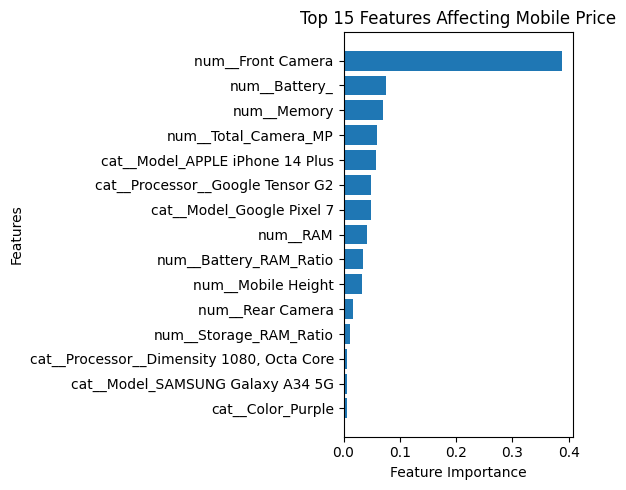

In [ ]:
#Visualize feature importance
top_features = importance_df.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(6,5))
plt.barh(
    top_features['Feature'],
    top_features['Importance']
)
plt.title('Top 15 Features Affecting Mobile Price')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [ ]:
 #Select important features automatically
selector = SelectFromModel(
    model,
    threshold='median',
    prefit=True
)

X_train_selected = selector.transform(X_train_processed)
X_test_selected = selector.transform(X_test_processed)

selected_features = feature_names[selector.get_support()]

print("\nSelected Features:")
print(selected_features.tolist())

print("\nNumber of features before selection:",
      X_train_processed.shape[1])

print("Number of features after selection:",
      X_train_selected.shape[1])


Selected Features:
['num__Memory', 'num__RAM', 'num__Battery_', 'num__Rear Camera', 'num__Front Camera', 'num__AI Lens', 'num__Mobile Height', 'num__Total_Camera_MP', 'num__Storage_RAM_Ratio', 'num__Battery_RAM_Ratio', 'cat__Model_APPLE iPhone 11', 'cat__Model_APPLE iPhone 12', 'cat__Model_APPLE iPhone 14 Plus', 'cat__Model_Google Pixel 6a', 'cat__Model_Google Pixel 7', 'cat__Model_Google Pixel 7a', 'cat__Model_IQOO Neo 7 5G', 'cat__Model_Infinix HOT 20 5G', 'cat__Model_Infinix HOT 30i', 'cat__Model_Infinix Hot 12 Pro', 'cat__Model_Infinix Note 12 Pro 5G', 'cat__Model_Infinix Zero 20', 'cat__Model_Infinix Zero 5G 2023', 'cat__Model_Infinix Zero 5G 2023 TURBO', 'cat__Model_MOTOROLA Edge 30', 'cat__Model_MOTOROLA Edge 30 Fusion', 'cat__Model_MOTOROLA Edge 30 Ultra', 'cat__Model_MOTOROLA Edge 40', 'cat__Model_MOTOROLA G32', 'cat__Model_MOTOROLA G62 5G', 'cat__Model_MOTOROLA e13', 'cat__Model_MOTOROLA e32', 'cat__Model_MOTOROLA g13', 'cat__Model_MOTOROLA g52', 'cat__Model_MOTOROLA g72', '